# Comparative Analysis of Classification Algorithms
**SVM · Decision Tree · K-Nearest Neighbours · Naïve Bayes**

**Aim:** Develop four classification models, evaluate them using Accuracy, Precision, Recall, F1-score and Loss (Log-loss), and compare their suitability for different classification tasks.

**Datasets (all built into scikit-learn, no download needed, free to run in Google Colab):**
1. Breast Cancer Wisconsin – binary, 30 numeric features (main experiment)
2. Wine – 3 classes, 13 features, small data (generalisation check)
3. Digits – 10 classes, 64 features (high-dimensional multiclass check)

> Run: `Runtime → Run all`. Total run time ≈ 1–2 minutes.

## 1. Import libraries

In [1]:
import time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer, load_wine, load_digits
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_validate, learning_curve
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             log_loss, roc_auc_score, roc_curve, confusion_matrix,
                             ConfusionMatrixDisplay, classification_report)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
print("Libraries loaded.")

Libraries loaded.


## 2. Load and explore the dataset (Breast Cancer Wisconsin)

In [2]:
data = load_breast_cancer(as_frame=True)
X, y = data.data, data.target          # 0 = malignant, 1 = benign
print("Shape:", X.shape)
print("Missing values:", int(X.isna().sum().sum()))
print("Class distribution:\n", y.value_counts().rename({0:'malignant', 1:'benign'}))
X.describe().T.head(10)

Shape: (569, 30)
Missing values: 0
Class distribution:
 target
benign       357
malignant    212
Name: count, dtype: int64


,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.98100,11.70000,13.37000,15.78000,28.11000
mean texture,569.0,19.289649,4.301036,9.71000,16.17000,18.84000,21.80000,39.28000
mean perimeter,569.0,91.969033,24.298981,43.79000,75.17000,86.24000,104.10000,188.50000
mean area,569.0,654.889104,351.914129,143.50000,420.30000,551.10000,782.70000,2501.00000
mean smoothness,569.0,0.096360,0.014064,0.05263,0.08637,0.09587,0.10530,0.16340
mean compactness,569.0,0.104341,0.052813,0.01938,0.06492,0.09263,0.13040,0.34540
mean concavity,569.0,0.088799,0.079720,0.00000,0.02956,0.06154,0.13070,0.42680
mean concave points,569.0,0.048919,0.038803,0.00000,0.02031,0.03350,0.07400,0.20120
mean symmetry,569.0,0.181162,0.027414,0.10600,0.16190,0.17920,0.19570,0.30400
mean fractal dimension,569.0,0.062798,0.007060,0.04996,0.05770,0.06154,0.06612,0.09744


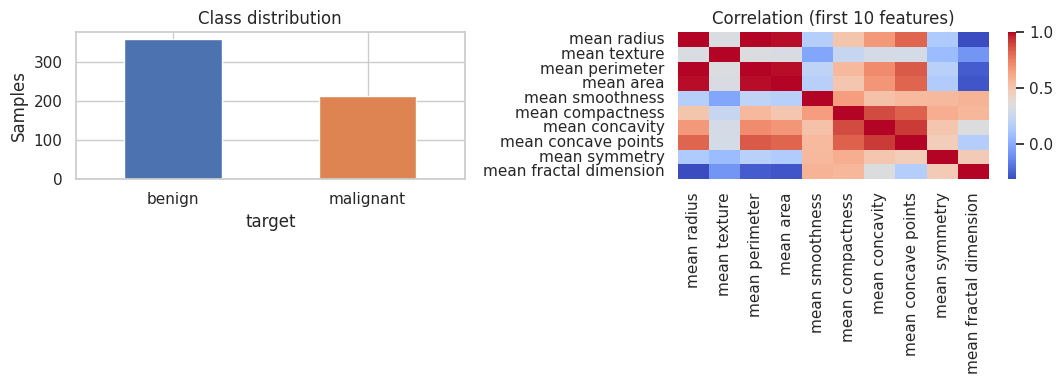

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
y.map({0:'malignant', 1:'benign'}).value_counts().plot(kind='bar', ax=ax[0], color=['#4C72B0', '#DD8452'])
ax[0].set_title('Class distribution'); ax[0].set_ylabel('Samples'); ax[0].tick_params(axis='x', rotation=0)
sns.heatmap(X.iloc[:, :10].corr(), cmap='coolwarm', ax=ax[1], cbar=True)
ax[1].set_title('Correlation (first 10 features)')
plt.tight_layout(); plt.show()

## 3. Train / test split
80 % training, 20 % testing, **stratified** so both sets keep the same class ratio.
Scaling is placed **inside a Pipeline** so the scaler is fitted only on training data (no data leakage).
SVM and KNN are distance/margin based and need scaling; Decision Tree and Naïve Bayes do not, but it is harmless.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (455, 30)  Test: (114, 30)


## 4. Build models and tune hyper-parameters
`GridSearchCV` with 5-fold stratified cross-validation (optimising F1-score) is used on the **training set only**.

In [5]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

models = {
    "SVM": (Pipeline([("sc", StandardScaler()), ("clf", SVC(probability=True, random_state=RANDOM_STATE))]),
            {"clf__kernel": ["linear", "rbf"], "clf__C": [0.1, 1, 10, 100], "clf__gamma": ["scale", 0.01, 0.1]}),
    "Decision Tree": (Pipeline([("sc", StandardScaler()), ("clf", DecisionTreeClassifier(random_state=RANDOM_STATE))]),
            {"clf__criterion": ["gini", "entropy"], "clf__max_depth": [2, 3, 4, 5, 7, None],
             "clf__min_samples_leaf": [1, 3, 5, 10]}),
    "KNN": (Pipeline([("sc", StandardScaler()), ("clf", KNeighborsClassifier())]),
            {"clf__n_neighbors": [1, 3, 5, 7, 9, 11, 15], "clf__weights": ["uniform", "distance"],
             "clf__metric": ["euclidean", "manhattan"]}),
    "Naive Bayes": (Pipeline([("sc", StandardScaler()), ("clf", GaussianNB())]),
            {"clf__var_smoothing": np.logspace(-11, -1, 11)}),
}

best_models, tuning_rows = {}, []
for name, (pipe, grid) in models.items():
    t0 = time.time()
    gs = GridSearchCV(pipe, grid, cv=cv, scoring="f1", n_jobs=-1).fit(X_train, y_train)
    best_models[name] = gs.best_estimator_
    tuning_rows.append({"Model": name, "Best CV F1": round(gs.best_score_, 4),
                        "Best parameters": {k.replace("clf__", ""): v for k, v in gs.best_params_.items()},
                        "Tuning time (s)": round(time.time() - t0, 1)})
pd.DataFrame(tuning_rows).set_index("Model")

,Best CV F1,Best parameters,Tuning time (s)
Model,,,
SVM,0.9810,"{'C': 0.1, 'gamma': 'scale', 'kernel': 'linear'}",2.1
Decision Tree,0.9493,"{'criterion': 'entropy', 'max_depth': 4, 'min_...",2.2
KNN,0.9774,"{'metric': 'manhattan', 'n_neighbors': 3, 'wei...",0.8
Naive Bayes,0.9535,{'var_smoothing': 0.1},0.3


## 5. Evaluation on the unseen test set
Metrics: **Accuracy, Precision, Recall, F1-score, Log-loss (cross-entropy loss)** plus ROC-AUC.
Class 1 (benign) is the positive class (scikit-learn convention); the per-class report below shows both classes. In a clinical setting the recall of *malignant* (class 0) would also be watched closely.

In [6]:
def evaluate(model, X_tr, y_tr, X_te, y_te, average="binary"):
    t0 = time.time(); model.fit(X_tr, y_tr); fit_t = time.time() - t0
    t0 = time.time(); pred = model.predict(X_te); pred_t = time.time() - t0
    proba = model.predict_proba(X_te)
    row = {
        "Accuracy":  accuracy_score(y_te, pred),
        "Precision": precision_score(y_te, pred, average=average),
        "Recall":    recall_score(y_te, pred, average=average),
        "F1-score":  f1_score(y_te, pred, average=average),
        "Log-loss":  log_loss(y_te, proba, labels=model.classes_),
        "Train time (s)": fit_t, "Predict time (s)": pred_t,
    }
    if proba.shape[1] == 2: row["ROC-AUC"] = roc_auc_score(y_te, proba[:, 1])
    else:                   row["ROC-AUC"] = roc_auc_score(y_te, proba, multi_class="ovr", average="macro")
    return row, pred, proba

results, preds, probas = {}, {}, {}
for name, mdl in best_models.items():
    results[name], preds[name], probas[name] = evaluate(mdl, X_train, y_train, X_test, y_test)

res_df = pd.DataFrame(results).T
res_df.round(4)

,Accuracy,Precision,Recall,F1-score,Log-loss,Train time (s),Predict time (s),ROC-AUC
SVM,0.9825,0.9861,0.9861,0.9861,0.0858,0.0082,0.0012,0.9937
Decision Tree,0.8772,0.9531,0.8472,0.8971,1.0652,0.0073,0.0010,0.9593
KNN,0.9649,0.9595,0.9861,0.9726,0.6836,0.0023,0.0020,0.9714
Naive Bayes,0.9474,0.9459,0.9722,0.9589,0.3763,0.0028,0.0010,0.9878


In [7]:
print(res_df[["Accuracy","Precision","Recall","F1-score","Log-loss","ROC-AUC"]].round(4).to_string())
for name in best_models:
    print("\n" + "="*60 + f"\n{name}\n" + "="*60)
    print(classification_report(y_test, preds[name], target_names=["malignant", "benign"], digits=4))

               Accuracy  Precision  Recall  F1-score  Log-loss  ROC-AUC
SVM              0.9825     0.9861  0.9861    0.9861    0.0858   0.9937
Decision Tree    0.8772     0.9531  0.8472    0.8971    1.0652   0.9593
KNN              0.9649     0.9595  0.9861    0.9726    0.6836   0.9714
Naive Bayes      0.9474     0.9459  0.9722    0.9589    0.3763   0.9878

SVM
              precision    recall  f1-score   support

   malignant     0.9762    0.9762    0.9762        42
      benign     0.9861    0.9861    0.9861        72

    accuracy                         0.9825       114
   macro avg     0.9812    0.9812    0.9812       114
weighted avg     0.9825    0.9825    0.9825       114


Decision Tree
              precision    recall  f1-score   support

   malignant     0.7800    0.9286    0.8478        42
      benign     0.9531    0.8472    0.8971        72

    accuracy                         0.8772       114
   macro avg     0.8666    0.8879    0.8724       114
weighted avg     0.88

### 5.1 Confusion matrices

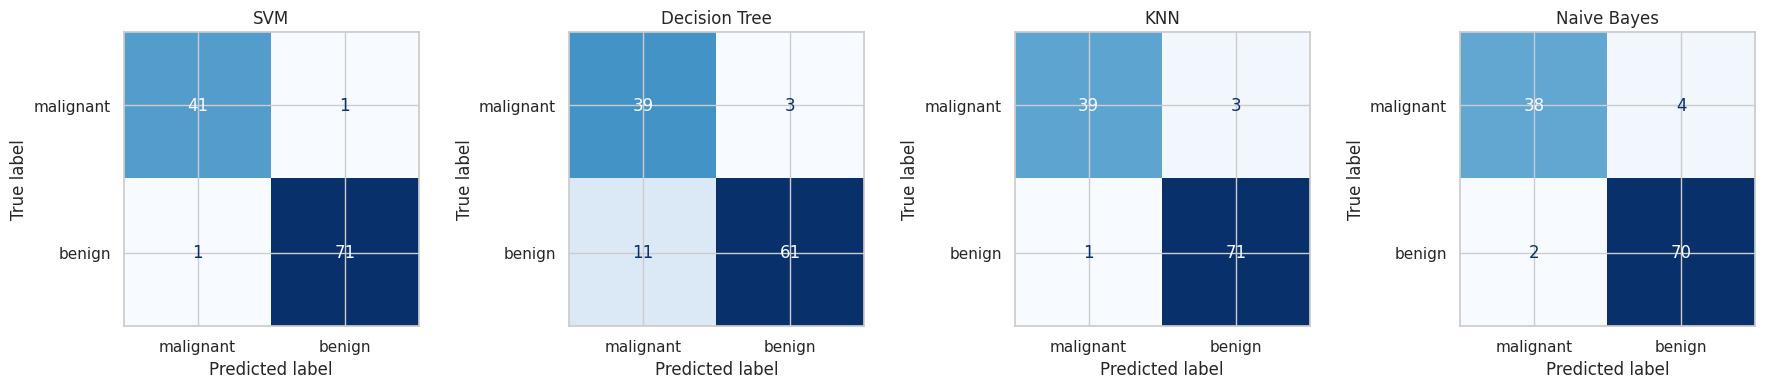

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, name in zip(axes, best_models):
    ConfusionMatrixDisplay(confusion_matrix(y_test, preds[name]),
                           display_labels=["malignant", "benign"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)
plt.tight_layout(); plt.show()

### 5.2 Metric comparison chart

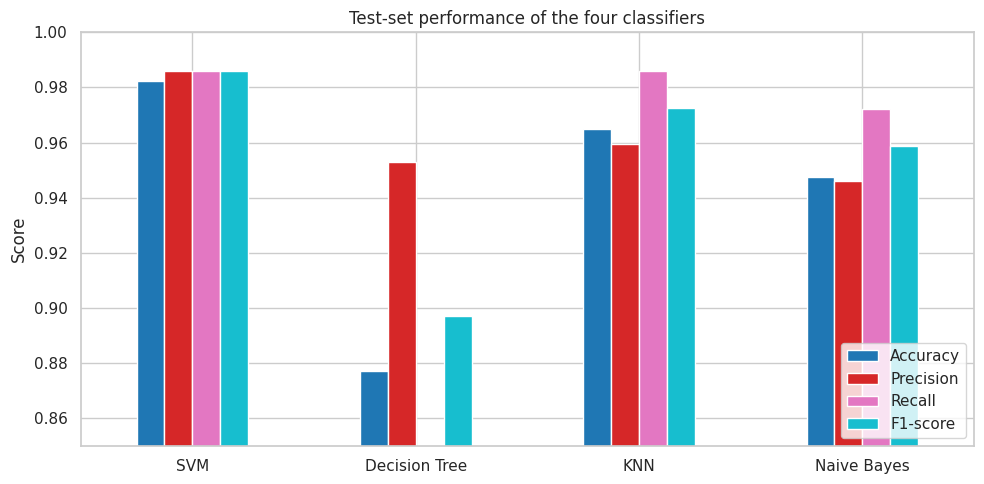

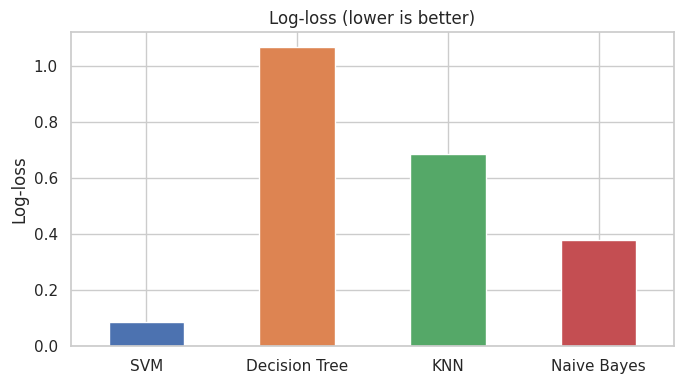

In [9]:
metrics = ["Accuracy", "Precision", "Recall", "F1-score"]
res_df[metrics].plot(kind="bar", figsize=(10, 5), ylim=(0.85, 1.0), rot=0, colormap="tab10")
plt.title("Test-set performance of the four classifiers"); plt.ylabel("Score")
plt.legend(loc="lower right"); plt.tight_layout(); plt.show()

res_df["Log-loss"].plot(kind="bar", figsize=(7, 4), color=["#4C72B0", "#DD8452", "#55A868", "#C44E52"], rot=0)
plt.title("Log-loss (lower is better)"); plt.ylabel("Log-loss"); plt.tight_layout(); plt.show()

### 5.3 ROC curves

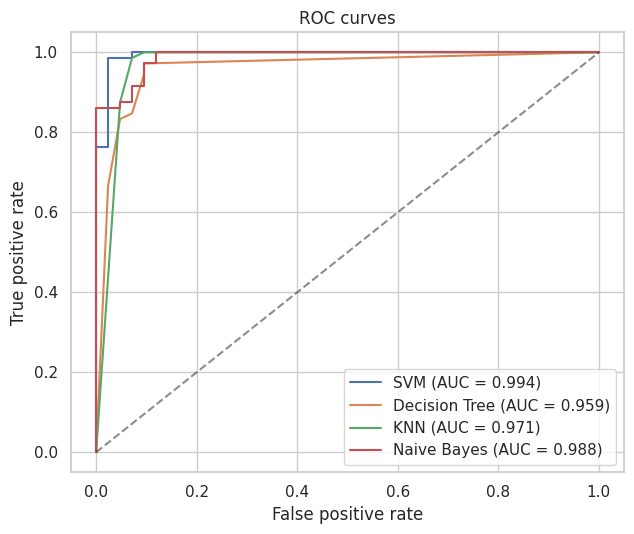

In [10]:
plt.figure(figsize=(6.5, 5.5))
for name in best_models:
    fpr, tpr, _ = roc_curve(y_test, probas[name][:, 1])
    plt.plot(fpr, tpr, label=f"{name} (AUC = {res_df.loc[name, 'ROC-AUC']:.3f})")
plt.plot([0, 1], [0, 1], "k--", alpha=.5)
plt.xlabel("False positive rate"); plt.ylabel("True positive rate"); plt.title("ROC curves")
plt.legend(loc="lower right"); plt.tight_layout(); plt.show()

## 6. Robustness: 5-fold cross-validation on the full dataset
A single train/test split can be lucky or unlucky, so the mean ± standard deviation over 5 folds is also reported.

In [11]:
scoring = {"accuracy": "accuracy", "precision": "precision", "recall": "recall", "f1": "f1", "neg_log_loss": "neg_log_loss"}
cv_rows = {}
for name, mdl in best_models.items():
    s = cross_validate(mdl, X, y, cv=cv, scoring=scoring, n_jobs=-1)
    cv_rows[name] = {m.replace("neg_", "").replace("_", "-").title():
                     f"{abs(s['test_'+m].mean()):.4f} ± {s['test_'+m].std():.4f}" for m in scoring}
cv_df = pd.DataFrame(cv_rows).T
cv_df

,Accuracy,Precision,Recall,F1,Log-Loss
SVM,0.9754 ± 0.0170,0.9683 ± 0.0290,0.9944 ± 0.0069,0.9809 ± 0.0130,0.0886 ± 0.0463
Decision Tree,0.9227 ± 0.0349,0.9214 ± 0.0553,0.9636 ± 0.0272,0.9405 ± 0.0248,1.1636 ± 0.2466
KNN,0.9666 ± 0.0188,0.9652 ± 0.0287,0.9833 ± 0.0162,0.9738 ± 0.0146,0.4300 ± 0.3719
Naive Bayes,0.9333 ± 0.0196,0.9284 ± 0.0224,0.9693 ± 0.0283,0.9479 ± 0.0155,0.6896 ± 0.3832


## 7. Loss and hyper-parameter behaviour (bias–variance)

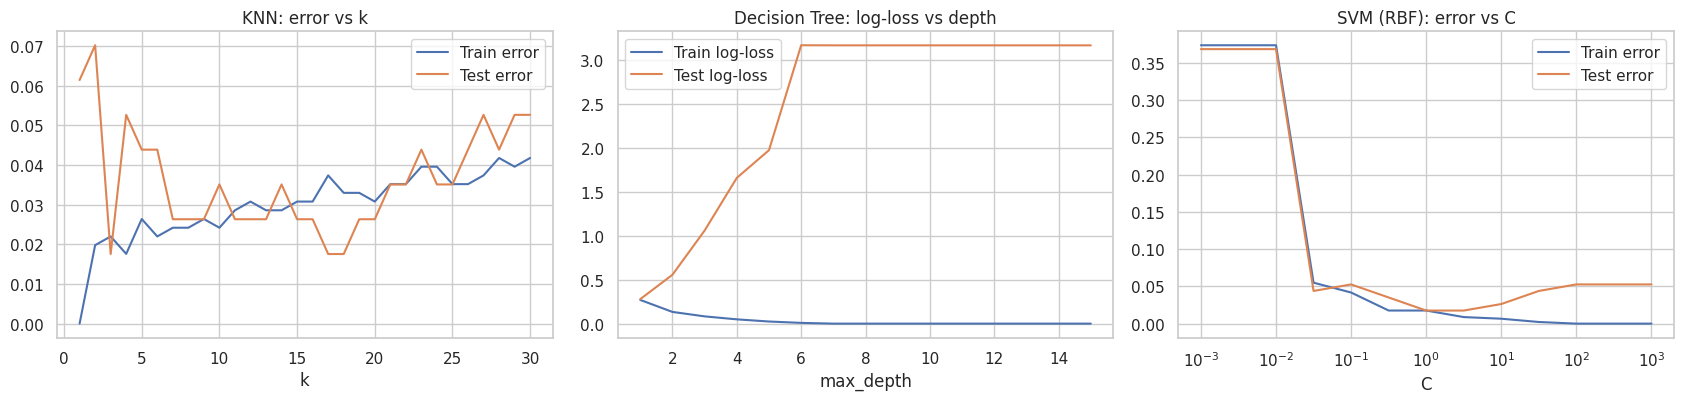

In [12]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))

# KNN: effect of k
ks = range(1, 31)
tr = [1 - Pipeline([("sc", StandardScaler()), ("k", KNeighborsClassifier(n_neighbors=k))]).fit(X_train, y_train).score(X_train, y_train) for k in ks]
te = [1 - Pipeline([("sc", StandardScaler()), ("k", KNeighborsClassifier(n_neighbors=k))]).fit(X_train, y_train).score(X_test, y_test) for k in ks]
ax[0].plot(ks, tr, label="Train error"); ax[0].plot(ks, te, label="Test error")
ax[0].set_title("KNN: error vs k"); ax[0].set_xlabel("k"); ax[0].legend()

# Decision tree: effect of depth
ds = range(1, 16)
tr, te = [], []
for d in ds:
    t = DecisionTreeClassifier(max_depth=d, random_state=RANDOM_STATE).fit(X_train, y_train)
    tr.append(log_loss(y_train, t.predict_proba(X_train))); te.append(log_loss(y_test, t.predict_proba(X_test)))
ax[1].plot(ds, tr, label="Train log-loss"); ax[1].plot(ds, te, label="Test log-loss")
ax[1].set_title("Decision Tree: log-loss vs depth"); ax[1].set_xlabel("max_depth"); ax[1].legend()

# SVM: effect of C
Cs = np.logspace(-3, 3, 13)
tr, te = [], []
for c in Cs:
    s = Pipeline([("sc", StandardScaler()), ("m", SVC(kernel="rbf", C=c, probability=True, random_state=RANDOM_STATE))]).fit(X_train, y_train)
    tr.append(1 - s.score(X_train, y_train)); te.append(1 - s.score(X_test, y_test))
ax[2].semilogx(Cs, tr, label="Train error"); ax[2].semilogx(Cs, te, label="Test error")
ax[2].set_title("SVM (RBF): error vs C"); ax[2].set_xlabel("C"); ax[2].legend()
plt.tight_layout(); plt.show()

### Learning curves (how much data does each model need?)

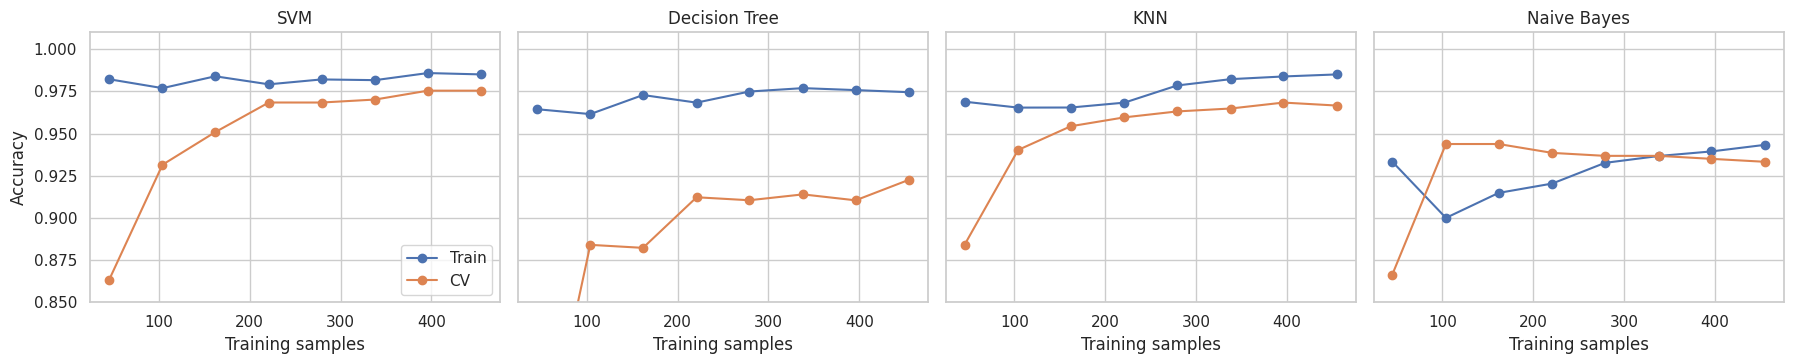

In [13]:
fig, axes = plt.subplots(1, 4, figsize=(18, 3.8), sharey=True)
for ax, (name, mdl) in zip(axes, best_models.items()):
    sizes, trs, vals = learning_curve(mdl, X, y, cv=cv, train_sizes=np.linspace(0.1, 1.0, 8), scoring="accuracy", n_jobs=-1)
    ax.plot(sizes, trs.mean(1), "o-", label="Train"); ax.plot(sizes, vals.mean(1), "o-", label="CV")
    ax.set_title(name); ax.set_xlabel("Training samples"); ax.set_ylim(0.85, 1.01)
axes[0].set_ylabel("Accuracy"); axes[0].legend(); plt.tight_layout(); plt.show()

### Decision-tree interpretability: the learned rules and feature importance

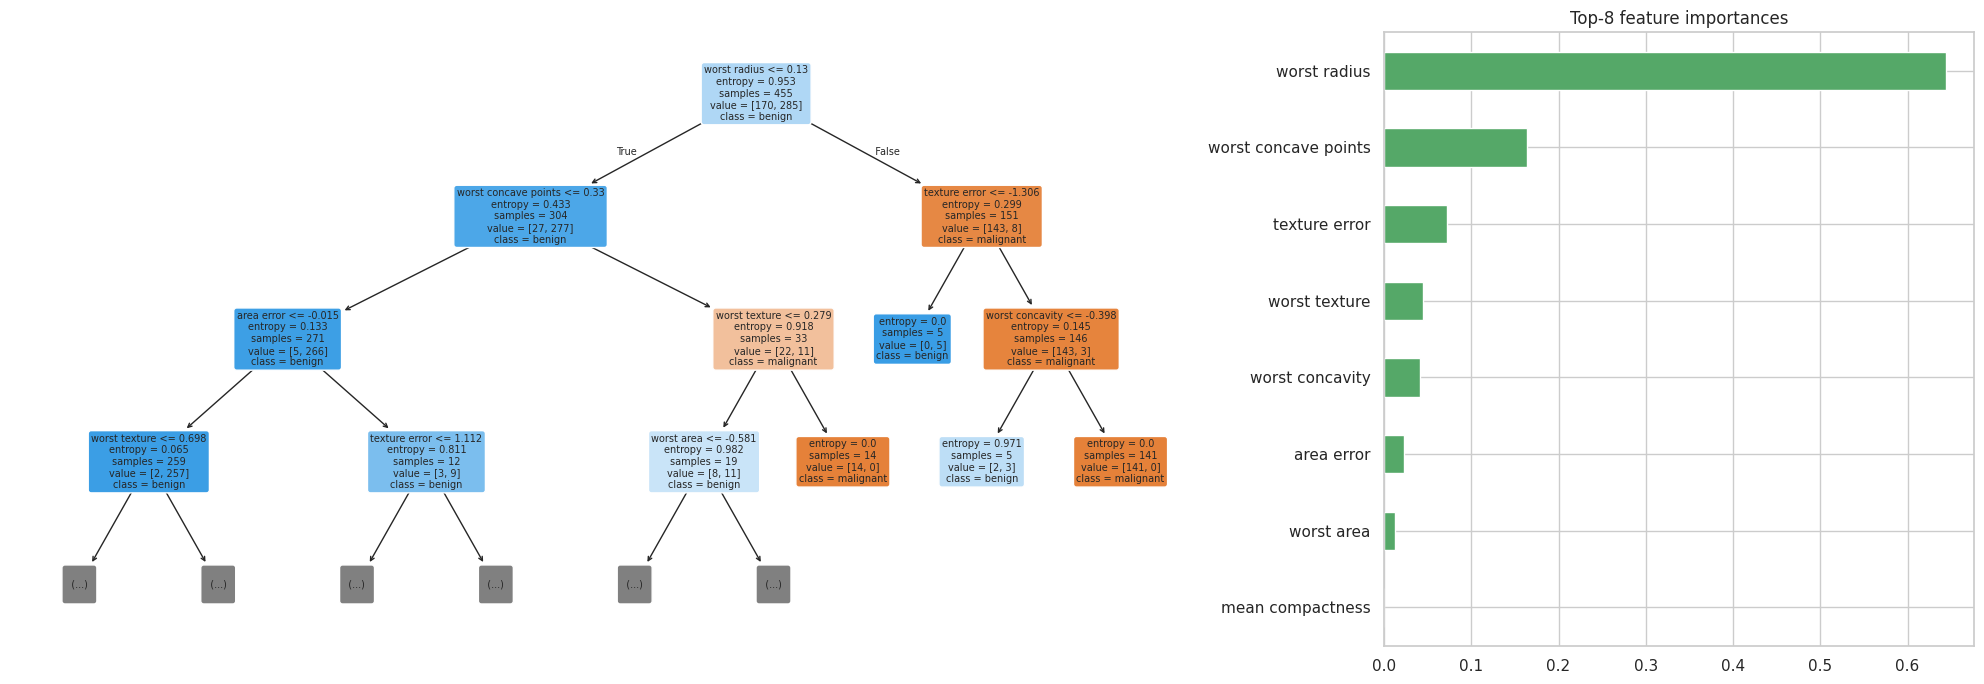

In [14]:
dt = best_models["Decision Tree"].named_steps["clf"]
fig, ax = plt.subplots(1, 2, figsize=(20, 7), gridspec_kw={"width_ratios": [2, 1]})
plot_tree(dt, feature_names=X.columns, class_names=["malignant", "benign"], filled=True, rounded=True, fontsize=7, ax=ax[0], max_depth=3)
imp = pd.Series(dt.feature_importances_, index=X.columns).sort_values(ascending=False).head(8)
imp[::-1].plot(kind="barh", ax=ax[1], color="#55A868"); ax[1].set_title("Top-8 feature importances")
plt.tight_layout(); plt.show()

## 8. Generalisation to other classification tasks
To discuss *suitability* the same four algorithms (default tuning grids, re-tuned per dataset) are applied to two more tasks:
* **Wine** – small dataset (178 samples), 3 classes
* **Digits** – 1,797 samples, 64 features, 10 classes (macro-averaged metrics)

In [15]:
def run_dataset(loader, name):
    d = loader(as_frame=False); Xd, yd = d.data, d.target
    Xtr, Xte, ytr, yte = train_test_split(Xd, yd, test_size=0.2, stratify=yd, random_state=RANDOM_STATE)
    grids = {
        "SVM": (SVC(probability=True, random_state=RANDOM_STATE), {"clf__C": [0.1, 1, 10, 100], "clf__gamma": ["scale", 0.001, 0.01], "clf__kernel": ["rbf", "linear"]}),
        "Decision Tree": (DecisionTreeClassifier(random_state=RANDOM_STATE), {"clf__max_depth": [3, 5, 8, None], "clf__min_samples_leaf": [1, 3, 5]}),
        "KNN": (KNeighborsClassifier(), {"clf__n_neighbors": [1, 3, 5, 7, 9], "clf__weights": ["uniform", "distance"]}),
        "Naive Bayes": (GaussianNB(), {"clf__var_smoothing": np.logspace(-11, -1, 11)}),
    }
    rows = {}
    for mname, (est, g) in grids.items():
        pipe = Pipeline([("sc", StandardScaler()), ("clf", est)])
        gs = GridSearchCV(pipe, g, cv=cv, scoring="f1_macro", n_jobs=-1).fit(Xtr, ytr)
        r, _, _ = evaluate(gs.best_estimator_, Xtr, ytr, Xte, yte, average="macro")
        rows[mname] = r
    out = pd.DataFrame(rows).T
    out.insert(0, "Dataset", name)
    return out

wine_df   = run_dataset(load_wine, "Wine")
digits_df = run_dataset(load_digits, "Digits")
other = pd.concat([wine_df, digits_df])
other[["Dataset", "Accuracy", "Precision", "Recall", "F1-score", "Log-loss", "ROC-AUC", "Train time (s)"]].round(4)

,Dataset,Accuracy,Precision,Recall,F1-score,Log-loss,ROC-AUC,Train time (s)
SVM,Wine,0.9722,0.9778,0.9667,0.9710,0.0924,1.0000,0.0030
Decision Tree,Wine,0.9444,0.9583,0.9389,0.9457,2.0024,0.9543,0.0017
KNN,Wine,1.0000,1.0000,1.0000,1.0000,0.0937,1.0000,0.0009
Naive Bayes,Wine,0.9722,0.9744,0.9762,0.9743,0.0293,1.0000,0.0012
SVM,Digits,0.9750,0.9760,0.9748,0.9748,0.1181,0.9995,0.2163
Decision Tree,Digits,0.8028,0.8039,0.8019,0.8014,5.0151,0.9223,0.0171
KNN,Digits,0.9667,0.9678,0.9664,0.9663,0.6337,0.9907,0.0020
Naive Bayes,Digits,0.8917,0.8947,0.8908,0.8918,1.2879,0.9798,0.0041


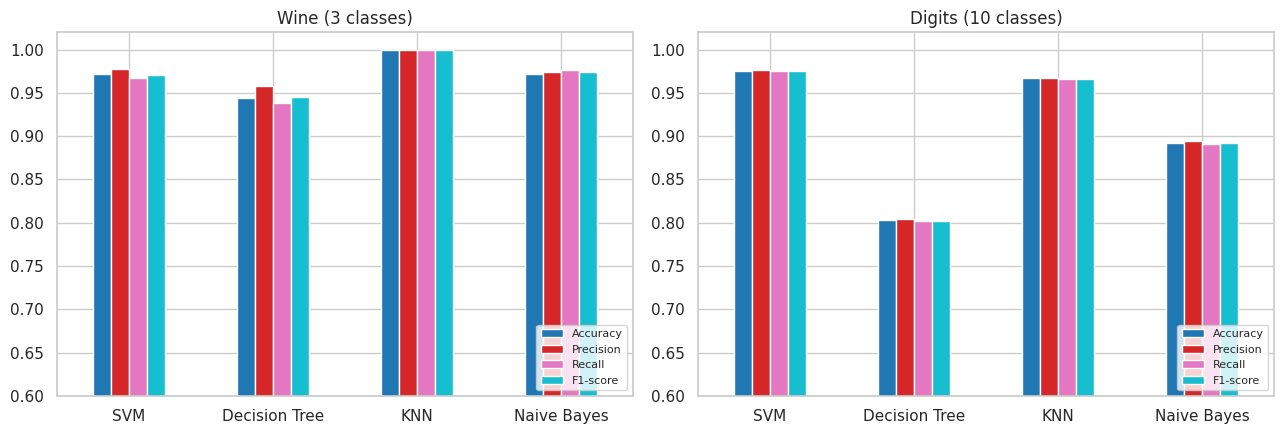

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for a, (df, t) in zip(ax, [(wine_df, "Wine (3 classes)"), (digits_df, "Digits (10 classes)")]):
    df[["Accuracy", "Precision", "Recall", "F1-score"]].plot(kind="bar", ax=a, rot=0, ylim=(0.6, 1.02), colormap="tab10")
    a.set_title(t); a.legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.show()

## 9. Master comparison table (all tasks)

In [17]:
summary = pd.concat([res_df.assign(Dataset="Breast Cancer").reset_index().rename(columns={"index":"Model"}),
                     other.reset_index().rename(columns={"index":"Model"})])
summary = summary[["Dataset", "Model", "Accuracy", "Precision", "Recall", "F1-score", "Log-loss", "ROC-AUC", "Train time (s)"]].round(4)
summary.to_csv("classification_results.csv", index=False)
summary

,Dataset,Model,Accuracy,Precision,Recall,F1-score,Log-loss,ROC-AUC,Train time (s)
0,Breast Cancer,SVM,0.9825,0.9861,0.9861,0.9861,0.0858,0.9937,0.0082
1,Breast Cancer,Decision Tree,0.8772,0.9531,0.8472,0.8971,1.0652,0.9593,0.0073
2,Breast Cancer,KNN,0.9649,0.9595,0.9861,0.9726,0.6836,0.9714,0.0023
3,Breast Cancer,Naive Bayes,0.9474,0.9459,0.9722,0.9589,0.3763,0.9878,0.0028
0,Wine,SVM,0.9722,0.9778,0.9667,0.9710,0.0924,1.0000,0.0030
1,Wine,Decision Tree,0.9444,0.9583,0.9389,0.9457,2.0024,0.9543,0.0017
2,Wine,KNN,1.0000,1.0000,1.0000,1.0000,0.0937,1.0000,0.0009
3,Wine,Naive Bayes,0.9722,0.9744,0.9762,0.9743,0.0293,1.0000,0.0012
4,Digits,SVM,0.9750,0.9760,0.9748,0.9748,0.1181,0.9995,0.2163
5,Digits,Decision Tree,0.8028,0.8039,0.8019,0.8014,5.0151,0.9223,0.0171


In [18]:
# Average rank of each model across the three tasks (1 = best F1)
rank = summary.assign(rank=summary.groupby("Dataset")["F1-score"].rank(ascending=False, method="min"))
print(rank.pivot(index="Model", columns="Dataset", values="rank").assign(Average=lambda d: d.mean(axis=1)).sort_values("Average"))

Dataset        Breast Cancer  Digits  Wine   Average
Model                                               
KNN                      2.0     2.0   1.0  1.666667
SVM                      1.0     1.0   3.0  1.666667
Naive Bayes              3.0     3.0   2.0  2.666667
Decision Tree            4.0     4.0   4.0  4.000000


## 10. Findings and discussion

(Numbers quoted below come from the run above; re-running with the same `random_state=42` reproduces them.)

| Algorithm | Strengths | Weaknesses | Best suited for |
|---|---|---|---|
| **SVM** | High accuracy on high-dimensional, scaled data; robust through margin maximisation; kernels handle non-linear boundaries | Needs scaling and tuning (C, γ); slow on very large datasets; probabilities need extra calibration; hard to interpret | Medium-sized, high-dimensional problems (medical diagnosis, text, images) |
| **Decision Tree** | Fully interpretable rules; no scaling needed; handles mixed feature types; very fast prediction | High variance – overfits easily, unstable to small data changes; usually lower accuracy and worse log-loss than the others | Tasks where explanation matters (credit, rule-based triage); base learner for Random Forest / Boosting |
| **KNN** | No training phase; simple; naturally multiclass; strong on well-clustered, low-noise data | Slow prediction on large data; sensitive to scaling, irrelevant features and the curse of dimensionality; stores all data | Small/medium datasets, recommendation, quick baselines |
| **Naïve Bayes** | Extremely fast; works with very little data; well-calibrated-ish probabilities when assumptions roughly hold; scales to huge feature spaces | Assumes feature independence (violated here, so over-confident probabilities and higher log-loss); weaker when features are strongly correlated | Text / spam classification, real-time prediction, tiny datasets |

### Observed results (random_state = 42)
* **Breast Cancer:** SVM 98.25 % accuracy (F1 0.986, log-loss 0.086) > KNN 96.49 % > Naïve Bayes 94.74 % > Decision Tree 87.72 %. 5-fold CV confirms the same order (SVM 97.5 %, KNN 96.7 %, NB 93.3 %, DT 92.3 %).
* **Wine:** KNN reached 100 %, SVM and Naïve Bayes 97.2 %, Decision Tree 94.4 %; Naïve Bayes had the lowest log-loss (0.029).
* **Digits:** SVM 97.5 % > KNN 96.7 % > Naïve Bayes 89.2 % > Decision Tree 80.3 %; Decision Tree log-loss was 5.0 (very over-confident).
* **Loss:** SVM and (on small data) Naïve Bayes gave the lowest log-loss; Decision Trees were always worst because leaf probabilities are 0/1, which are punished heavily when wrong; KNN with small k behaves similarly.
* **Average F1 rank over the 3 tasks:** SVM and KNN tied (1.67), Naïve Bayes 2.67, Decision Tree 4.0.

### Conclusion
No single algorithm wins everywhere. Use the results table above to pick the winner for each dataset, then apply the guideline: **SVM** is the safest high-accuracy choice for numeric, scaled, medium-sized data; **KNN** is competitive on small clean data but degrades with dimensionality and cost at prediction time; **Decision Trees** trade some accuracy for transparency; **Naïve Bayes** is the fastest and most data-efficient baseline but is limited by its independence assumption.